In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)   # float64, so IPOPT's tight tolerances are meaningful (JAX defaults to float32)
import jax.numpy as jnp
import cyipopt
from scipy.linalg import solve_discrete_are, block_diag   # Riccati solver for the hold-phase LQR / LQI

np.random.seed(0)

In [2]:
# global constants
g = 9.81 # gravity(m/s^2)
m1 = m2 = 1 # mass of the two "spheres" of the pendulum(kg)
l1 = l2 = 0.5 # pendulum lengths(m)
dt = 0.05 # discretization time

u_min   = -10.0 # min control
u_max   = 10.0  # max control

def dynamics(x, u):
    q1, q2, q1_dot, q2_dot = x
    u1, u2 = u
    q_dot = jnp.array([q1_dot, q2_dot])
    
    # Forward dynamics matrices (for the q_ddot)
    M = jnp.array([
        [l1**2 * m1 + l2**2 * m2 + l1**2 * m2 + 2*l1*m2*l2*jnp.cos(q2), l2**2 * m2 + l1*m2*l2*jnp.cos(q2)],
        [l2**2 * m2 + l1*m2*l2*jnp.cos(q2), l2**2 * m2]
    ])

    C = jnp.array([
        [-2*q2_dot*l1*m2*l2*jnp.sin(q2), -q2_dot*l1*m2*l2*jnp.sin(q2)],
        [q1_dot*l1*m2*l2*jnp.sin(q2), 0]
    ])

    G = jnp.array([
        -g*m1*l1*jnp.sin(q1) - g*m2*(l1*jnp.sin(q1) + l2*jnp.sin(q1 + q2)), -g*m2*l2*jnp.sin(q1 + q2)
    ])

    # Forward dynamics
    b = jnp.array([u1, u2]) - C @ q_dot + G
    q_ddot = jnp.linalg.solve(M, b)
    q1_ddot, q2_ddot = q_ddot

    x_dot = jnp.array([q1_dot, q2_dot, q1_ddot, q2_ddot])
    return x_dot

In [3]:
def rk4(x, u):
    f1 = dynamics(x, u)
    f2 = dynamics(x + f1*dt/2, u)
    f3 = dynamics(x + f2*dt/2, u)
    f4 = dynamics(x + f3*dt, u)

    x_n = x + (dt/6) * (f1 + 2*f2 + 2*f3 + f4) # next discretized state
    return x_n

# Discretize f
def f_discrete(x, u):
    return rk4(x, u)

In [4]:
# Simulation Data
T = 5 # simulation time
K = 100
print("K =", K)

K = 100


In [5]:
# Helper variables
N = 4 # state size
M = 2 # control input
h = dt # t_k+1 - t_k

x0 = jnp.array([0., 0., 0., 0.])        # hanging down
xf = jnp.array([jnp.pi, 0., 0., 0.])    # upright (top vertical)

In [6]:
# Objective - Minimal Control Effort

''' 
The cost (J) includes the midpoints controls Um (Simpson weights h/6, 4h/6, h/6).
If only the knot controls U are penalised, the optimizer hides its effort in the free
midpoint controls Um (which are then thrown away when we keep only U_nom).

'''
def objective(z):
    offset = (K + 1) * N # we skip over the states
    U = z[offset: offset + (K + 1) * M].reshape((K+1, M))
    um_offset = (K + 1) * (N + M) + K * N
    Um = z[um_offset: um_offset + K * M].reshape((K, M))

    J = (h/6) * (jnp.sum(U[:-1]**2) + 4*jnp.sum(Um**2) + jnp.sum(U[1:]**2))
    return J

In [7]:
def herm_simps_constraints(xk, xk1, xm, uk, uk1, um):
    fk = dynamics(xk, uk)
    fk1 = dynamics(xk1, uk1)
    fm = dynamics(xm, um)

    c1 = xk1 - xk - (h/6) * (fk + 4*fm + fk1) # Simpson constraint
    c2 = xm - 0.5 * (xk1 + xk) - (h/8) * (fk - fk1) # Hermite midpoint constraint
    
    return jnp.concatenate([c1, c2])

# Constraints function
def constraints(z):
    c = [] # Initialize

    # Extract knot and middle points
    idx = 0
    X = z[idx : idx + (K + 1) * N].reshape((K+1, N)) # extract all states x0, x1, ..., xk     (K+1)xN vector
    idx += (K + 1) * N # Finished extracting states x, moving on (to controls u)  

    U = z[idx : idx + (K + 1) * M].reshape((K+1, M)) # extract all controls u0, u1, ..., uk     (K+1)xM vector
    idx += (K + 1) * M # Finished extracting controls u, moving on (to middle points xm)

    Xm = z[idx : idx + K * N].reshape((K, N)) # extract all middle states xm    KxN vector
    idx += K * N

    Um = z[idx : idx + K * M].reshape((K, M)) # extract all middle controls um    KxM vector

    defects = jax.vmap(herm_simps_constraints)(             # shape (K, 2*N)
        X[:-1], X[1:], Xm,      # States: k, k+1, mid
        U[:-1], U[1:], Um       # Controls: k, k+1, mid
    )
    
    # Boundary constraints
    x0_constr = X[0] - jnp.array([0., 0., 0., 0.])
    xf_constr = X[-1] - jnp.array([jnp.pi, 0., 0., 0.])

    return jnp.concatenate([x0_constr, xf_constr, defects.flatten()])

In [8]:
# For faster JAX
jit_objective = jax.jit(objective)
jit_gradient = jax.jit(jax.grad(objective))
jit_constraints = jax.jit(constraints)
jit_jacobian = jax.jit(jax.jacfwd(constraints))

n_vars = (K+1)*(N+M) + K*(N+M)
m = constraints(jnp.zeros(n_vars)).size

# Use random data to ensure we don't accidentally get zeros that are actually structurally non-zero.
z_random = np.random.randn(n_vars)
J_dense = np.array(jit_jacobian(z_random))

# Find indices where Jacobian is NOT zero
J_rows, J_cols = np.nonzero(np.abs(J_dense) > 1e-9)
num_nonzero = len(J_rows)

class TrajOpt:
    def objective(self, z):
        return float(jit_objective(z))

    def gradient(self, z):
        return np.array(jit_gradient(z), dtype=np.float64).flatten()

    def constraints(self, z):
        return np.array(jit_constraints(z), dtype=np.float64).flatten()

    def jacobian(self, z):
        J = np.array(jit_jacobian(z), dtype=np.float64)
        return J[J_rows, J_cols]
    
    def jacobianstructure(self):
        return (J_rows, J_cols)
    
    def intermediate(self, alg_mod, iter_count, obj_value, inf_pr, inf_du, mu,
                     d_norm, regularization_size, alpha_du, alpha_pr, ls_trials):
        
        msg = "Iter #{:d} | Obj: {:.5g} | Infeasibility: {:.5g}"

        print(msg.format(iter_count, obj_value, inf_pr))

In [23]:
lb = -np.inf * np.ones(n_vars) # left bound
ub =  np.inf * np.ones(n_vars) # upper bound

cl = np.zeros(m)
cu = np.zeros(m)

# Constrain controls
u_start = (K+1)*N
u_end = u_start + (K+1)*M
lb[u_start:u_end] = u_min
ub[u_start:u_end] = u_max

# Constrain middle controls as well
um_start = u_end + K*N
um_end = um_start + K*M
lb[um_start:um_end] = u_min
ub[um_start:um_end] = u_max

# Initial guess is a straight line in state space from x0 to xf 
# This gives a warm start to the solver 
x0_np, xf_np = np.array(x0), np.array(xf)
s_knot = np.linspace(0, 1, K+1)[:, None]
s_mid  = ((np.arange(K) + 0.5) / K)[:, None]
z0 = np.concatenate([
    (x0_np + (xf_np - x0_np) * s_knot).ravel(),   # X
    np.zeros((K+1) * M),                          # U
    (x0_np + (xf_np - x0_np) * s_mid).ravel(),    # Xm
    np.zeros(K * M)                               # Um
])

nlp = cyipopt.Problem(
    n=n_vars,
    m=m,
    problem_obj=TrajOpt(),
    lb=lb,
    ub=ub,
    cl=cl,
    cu=cu
)

nlp.add_option("max_iter", 500)
nlp.add_option("tol", 1e-4)
nlp.add_option("hessian_approximation", "limited-memory")
nlp.add_option("print_level", 5)

z_opt, info = nlp.solve(z0)

# Check the numerical status code
if info['status'] == 0:
    print("SUCCESS: Optimal Solution Found!")
else:
    print(f"FAILURE: Solver failed with status {info['status']}")

This is Ipopt version 3.11.9, running with linear solver mumps.
NOTE: Other linear solvers might be more efficient (see Ipopt documentation).

Number of nonzeros in equality constraint Jacobian...:     8208
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:     1206
                     variables with only lower bounds:        0
                variables with lower and upper bounds:      402
                     variables with only upper bounds:        0
Total number of equality constraints.................:      808
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

Iter #0 | Obj: 0 | Infeasibility: 0.98084
iter    objective    inf_pr   inf_du lg(mu)  

cost J = 8.6500 -- max |constraint| = 8.00e-08
max |U knots| = 5.37 -- max |Um mid| = 5.29 -- limit = 10.0


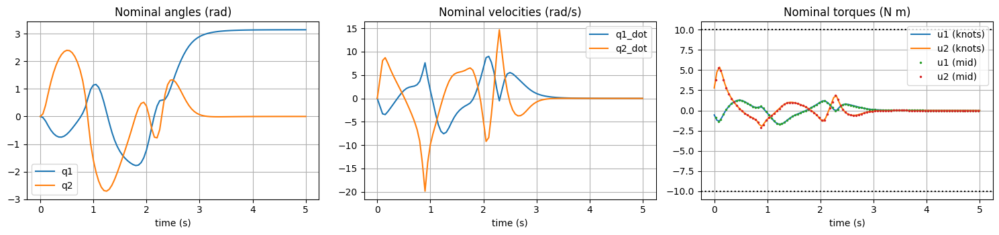

In [24]:
# Extract nominal knot points form ipopt
X_nom = z_opt[0 : (K + 1) * N].reshape((K + 1, N))
U_nom = z_opt[(K + 1) * N : (K + 1) * (N + M)].reshape((K + 1, M))
Um_nom = z_opt[(K + 1) * (N + M) + K * N :].reshape((K, M))

print(f"cost J = {float(objective(z_opt)):.4f} -- max |constraint| = {np.abs(np.array(constraints(z_opt))).max():.2e}")
print(f"max |U knots| = {np.abs(U_nom).max():.2f} -- max |Um mid| = {np.abs(Um_nom).max():.2f} -- limit = {u_max}")

# Plots for the nominal units
t_nom = np.arange(K + 1) * dt
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(t_nom, X_nom[:, 0], label="q1"); ax[0].plot(t_nom, X_nom[:, 1], label="q2"); ax[0].set_title("Nominal angles (rad)")
ax[1].plot(t_nom, X_nom[:, 2], label="q1_dot"); ax[1].plot(t_nom, X_nom[:, 3], label="q2_dot"); ax[1].set_title("Nominal velocities (rad/s)")
ax[2].plot(t_nom, U_nom[:, 0], label="u1 (knots)"); ax[2].plot(t_nom, U_nom[:, 1], label="u2 (knots)")
ax[2].plot(t_nom[:-1] + dt/2, Um_nom[:, 0], ".", ms=3, label="u1 (mid)"); ax[2].plot(t_nom[:-1] + dt/2, Um_nom[:, 1], ".", ms=3, label="u2 (mid)")
ax[2].axhline(u_max, c="k", ls=":"); ax[2].axhline(u_min, c="k", ls=":"); ax[2].set_title("Nominal torques (N m)")
for a in ax: a.grid(True); a.legend(); a.set_xlabel("time (s)")
plt.tight_layout(); plt.show()

In [25]:
# State and control weights
# The weights are chosen experimentally after many iterations of simulation 
Q = np.diag([100.0, 100.0, 10.0, 10.0])
R = np.diag([0.01, 0.01])

# Wrapper for RK4 to differentiate w.r.t x and u
rk4_jax = jax.jit(rk4)

get_A = jax.jit(jax.jacfwd(rk4_jax, 0)) # df/dx
get_B = jax.jit(jax.jacfwd(rk4_jax, 1)) # df/du

# Linearize at the equilibrium point (top vertical)
A_top = np.array(get_A(xf, jnp.zeros(M)))
B_top = np.array(get_B(xf, jnp.zeros(M)))

# Define a terminal cost by applying infinite-horizon LQR cost-to-go P_inf 
# This way, the end of TVLQR hands over smoothly to the infinite-horizon controller used at the top.
P_inf = solve_discrete_are(A_top, B_top, Q, R)
QN = P_inf # Final state cost

As = jax.vmap(get_A)(X_nom[:-1], U_nom[:-1])
Bs = jax.vmap(get_B)(X_nom[:-1], U_nom[:-1])

print(f"Linearized Model Shapes: A={As.shape}, B={Bs.shape}")

def tvlqr(As, Bs, Q, R, QN):
    K_gains = []
    P = QN # Start with final cost
    
    # Backward pass 
    for k in range(K-1, -1, -1):
        A = As[k]
        B = Bs[k]
        
        # K_k = -(R + B'PB)^-1 B'PA
        K_k = -jnp.linalg.solve(R + B.T @ P @ B, B.T @ P @ A)
        
        # P_k = Q + A'PA + A'PB K_k
        P = Q + A.T @ P @ A + A.T @ P @ B @ K_k
        
        K_gains.insert(0, K_k) # Store K gains in correct order
    return jnp.array(K_gains)

K_gains = tvlqr(As, Bs, Q, R, QN)

Linearized Model Shapes: A=(100, 4, 4), B=(100, 4, 2)


In [26]:
# Infinite-horizon LQR at the top (hold phase)
def solve_infinite_horizon_lqr(A, B, Q, R):
    P = solve_discrete_are(A, B, Q, R)
    return -np.linalg.solve(R + B.T @ P @ B, B.T @ P @ A)

K_inf = jnp.array(solve_infinite_horizon_lqr(A_top, B_top, Q, R)) # plain LQR, kept for comparison

# Infinite-horizon LQR withs integral action (LQI)
'''
    A plain state-feedback LQR recovers from a push, but a force 
    that stays on (constant load / sustained push) leaves a permanent offset. 
    The integrator on the two joint angles removes that offset.
'''
def solve_lqi(A, B, Q, R, q_int):
    n_x, n_u = B.shape
    C = np.zeros((2, n_x)); C[0, 0] = C[1, 1] = 1.0                   # integrate the angle errors (q1 - pi, q2)
    A_aug = np.block([[A, np.zeros((n_x, 2))], [dt * C, np.eye(2)]])   # z_{k+1} = z_k + dt * (q - q_goal)
    B_aug = np.vstack([B, np.zeros((2, n_u))])
    Q_aug = block_diag(Q, q_int * np.eye(2))
    P = solve_discrete_are(A_aug, B_aug, Q_aug, R)
    return -np.linalg.solve(R + B_aug.T @ P @ B_aug, B_aug.T @ P @ A_aug)

Q_INT = 200.0 # integral weight: larger = removes offsets faster, but more sensitive to noise
K_aug = jnp.array(solve_lqi(A_top, B_top, Q, R, Q_INT))

USE_INTEGRAL = True # False = plain K_inf in the hold phase
CLIP_TORQUE = True # apply the u_min/u_max actuator limit in the simulation (the NLP already assumes it)
z_int = np.zeros(2) # integrator state; reset before every simulation run

def my_controller(x_measured, k):
    global z_int
    
    # Stabilization after trajectory ends
    if k >= K:
        x_target = jnp.array([jnp.pi, 0, 0, 0])
        error = x_measured - x_target
        if USE_INTEGRAL:
            u = K_aug @ jnp.concatenate([error, jnp.array(z_int)])
            if bool(jnp.all(jnp.abs(u) <= u_max)):                        # anti-windup: only integrate while not saturated
                z_int = z_int + dt * np.array(error[:2], dtype=np.float64)
            return u
        return K_inf @ error # feedforward u_nom is zero at equilibrium
        
    # Nominal values for any timestep
    x_nom = X_nom[k]
    u_nom = U_nom[k]
    K_k = K_gains[k] # Gain at time k
    
    error = x_measured - x_nom # Error because of noise
    
    # Feedback law
    u_feedback = K_k @ error
    return u_nom + u_feedback # nominal (without noise) + feedback (for correction)

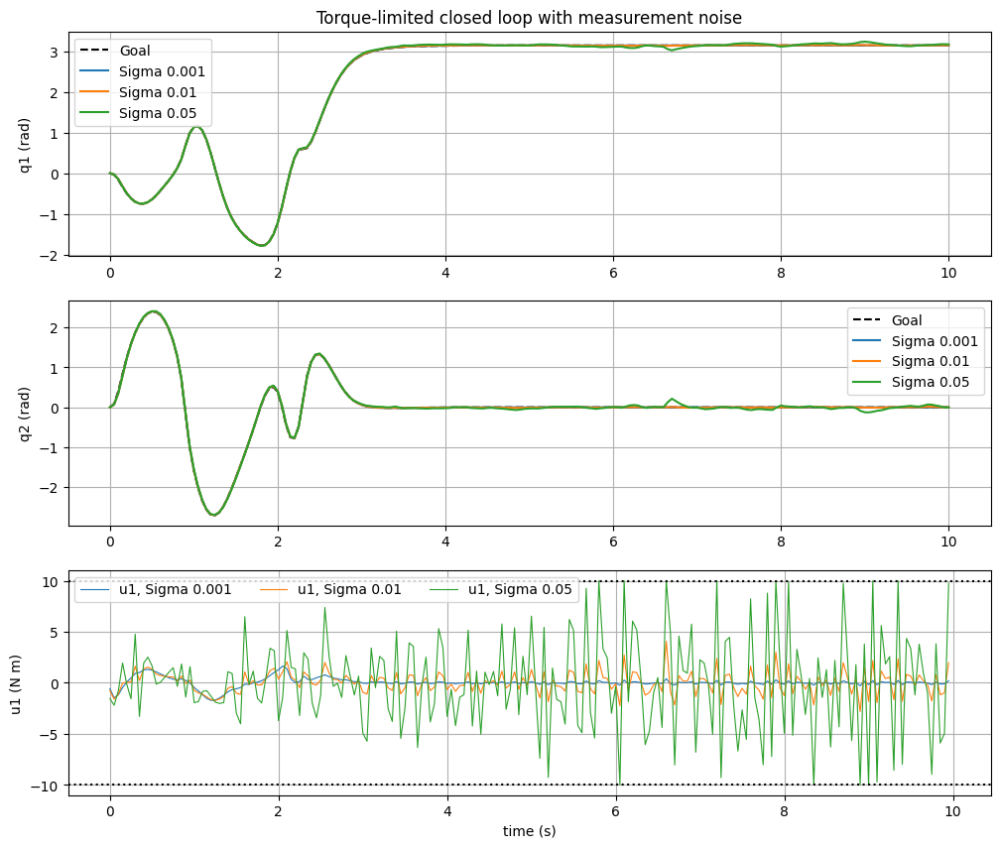

In [27]:
# Setup extended parameters 
extra_steps = 100 # Extra steps for when the trajectory ends
total_steps = K + extra_steps  # 100 + 100 = 200

# Extend the nominal points 
extense_X = jnp.tile(xf, (extra_steps, 1))
X_nom_extended = jnp.vstack([X_nom, extense_X])

def simulate(sigma=0.0, dist=None, use_integral=True, steps=total_steps, seed=0):
    # sigma: std of Gaussian measurement noise on the state
    # dist(k): extra joint torques acting on the PLANT at step k (a push / sustained force)
    global z_int, USE_INTEGRAL
    USE_INTEGRAL = use_integral
    z_int = np.zeros(2) # reset the integrator for every run
    rng = np.random.default_rng(seed)
    x_curr = x0
    x_history, u_history = [x0], []
    for k in range(steps):
        x_measured = x_curr + rng.normal(0, sigma, N) # Observed state with noise
        u = my_controller(x_measured, k) # Control input
        if CLIP_TORQUE:
            u = jnp.clip(u, u_min, u_max) # actuator limit
        d = jnp.zeros(M) if dist is None else dist(k)
        x_curr = rk4_jax(x_curr, u + d) # disturbance acts on the plant, not on the measurement
        x_history.append(x_curr)
        u_history.append(u + d)
    USE_INTEGRAL = True
    return np.array(x_history), np.array(u_history)

# Simulation with different noise levels and extended time
# Noise levels are chosen with regard to the max torques of the pendulum
noise_levels = [0.001, 0.01, 0.05]
results = [(sigma, *simulate(sigma=sigma, seed=1)) for sigma in noise_levels]

# Plots for all noise levels
t_plot = np.linspace(0, total_steps * dt, total_steps + 1)

plt.figure(figsize=(12, 10))
plt.subplot(3, 1, 1)
plt.plot(t_plot, X_nom_extended[:, 0], 'k--', label="Goal")
for sigma, x_res, _ in results:
    plt.plot(t_plot, x_res[:, 0], label=f"Sigma {sigma}")
plt.ylabel("q1 (rad)"); plt.legend(); plt.grid(True)
plt.title("Torque-limited closed loop with measurement noise")

plt.subplot(3, 1, 2)
plt.plot(t_plot, X_nom_extended[:, 1], 'k--', label="Goal")
for sigma, x_res, _ in results:
    plt.plot(t_plot, x_res[:, 1], label=f"Sigma {sigma}")
plt.ylabel("q2 (rad)"); plt.legend(); plt.grid(True)

plt.subplot(3, 1, 3)
for sigma, _, u_res in results:
    plt.plot(t_plot[:-1], u_res[:, 0], lw=0.8, label=f"u1, Sigma {sigma}")
plt.axhline(u_max, c="k", ls=":"); plt.axhline(u_min, c="k", ls=":")
plt.ylabel("u1 (N m)"); plt.xlabel("time (s)"); plt.legend(ncol=3); plt.grid(True)
plt.show()

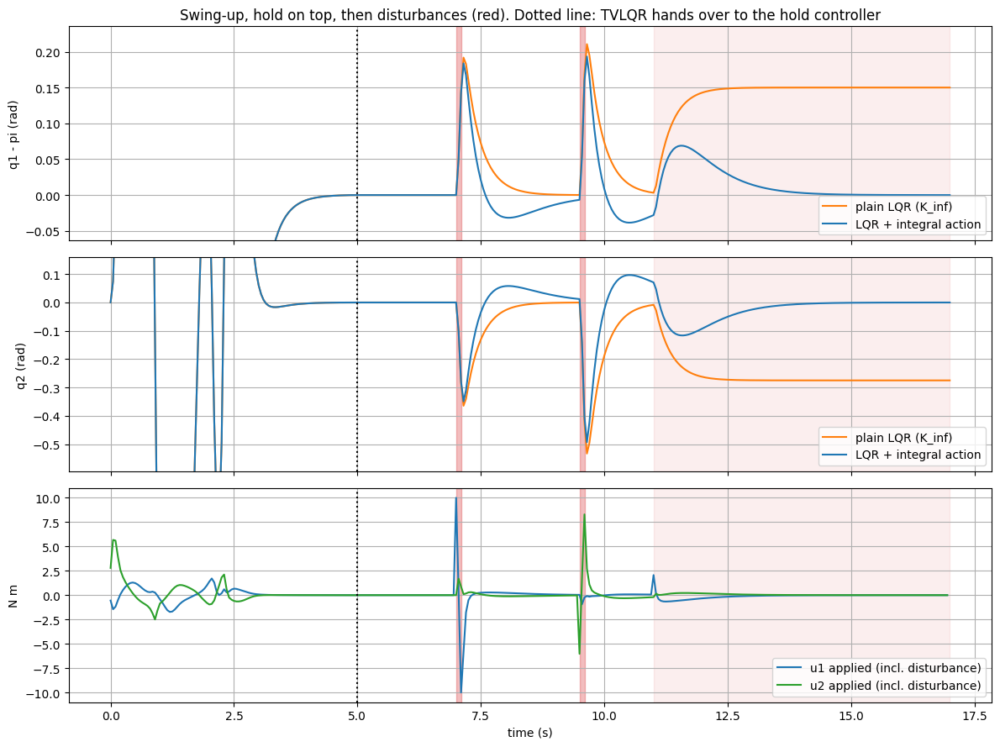

Final error under the sustained 2 N force:
  plain LQR (K_inf)       q1 +0.1500  q2 -0.2751
  LQR + integral action   q1 +0.0000  q2 -0.0000


In [29]:
# Stabilization on top + disturbance rejection

''' 
0-5 s     swing-up with TVLQR, then hold on top
# t = 7.0 s  push 1: +10 N on joint 1 for 0.1 s
# t = 9.5 s  push 2: -6 N on joint 2 for 0.1 s
# t >= 11 s  a constant 2 N on joint 1 that never goes away (sustained force)
 Disturbances are torques on the joints (a force F at the tip acts like the torque J^T F).
'''
push1_mag, push2_mag, force_const = 10.0, -6.0, 2.0   # N/m
T_SCEN = 17.0
steps_scen = int(round(T_SCEN / dt))
k_push1, k_push2, k_const = int(round(7.0/dt)), int(round(9.5/dt)), int(round(11.0/dt))
len_push = int(round(0.1/dt))

def scenario_dist(k):
    d = [0.0, 0.0]
    if k_push1 <= k < k_push1 + len_push: d[0] += push1_mag
    if k_push2 <= k < k_push2 + len_push: d[1] += push2_mag
    if k >= k_const:                      d[0] += force_const
    return jnp.array(d)

x_new, u_new = simulate(dist=scenario_dist, use_integral=True,  steps=steps_scen)   # TVLQR + LQR with integral action
x_old, u_old = simulate(dist=scenario_dist, use_integral=False, steps=steps_scen)   # TVLQR + plain LQR (K_inf)
t_s = np.arange(steps_scen + 1) * dt

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for a_i, (idx, off, lab) in enumerate([(0, np.pi, "q1 - pi (rad)"), (1, 0.0, "q2 (rad)")]):
    ax[a_i].plot(t_s, x_old[:, idx] - off, c="tab:orange", label="plain LQR (K_inf)")
    ax[a_i].plot(t_s, x_new[:, idx] - off, c="tab:blue", label="LQR + integral action")
    ax[a_i].set_ylabel(lab)
ax[2].plot(t_s[:-1], u_new[:, 0], c="tab:blue", label="u1 applied (incl. disturbance)")
ax[2].plot(t_s[:-1], u_new[:, 1], c="tab:green", label="u2 applied (incl. disturbance)")
ax[2].set_ylabel("N m"); ax[2].set_xlabel("time (s)")
for a in ax:
    a.axvspan(k_push1*dt, (k_push1+len_push)*dt, color="tab:red", alpha=0.3)
    a.axvspan(k_push2*dt, (k_push2+len_push)*dt, color="tab:red", alpha=0.3)
    a.axvspan(k_const*dt, T_SCEN, color="tab:red", alpha=0.08)
    a.axvline(K*dt, c="k", ls=":"); a.grid(True); a.legend(loc="lower right")
ax[0].set_title("Swing-up, hold on top, then disturbances (red). Dotted line: TVLQR hands over to the hold controller")
def hold_lim(idx, off):                       # zoom on the hold phase (the swing-up would be off-scale)
    seg = np.concatenate([x_new[K:, idx] - off, x_old[K:, idx] - off]); pad = 0.1 * (seg.max() - seg.min() + 1e-9)
    return seg.min() - pad, seg.max() + pad
ax[0].set_ylim(*hold_lim(0, np.pi)); ax[1].set_ylim(*hold_lim(1, 0.0))
plt.tight_layout(); plt.show()

e_new, e_old = x_new[-1] - np.array(xf), x_old[-1] - np.array(xf)
print("Final error under the sustained 2 N force:")
print(f"  plain LQR (K_inf)       q1 {e_old[0]:+.4f}  q2 {e_old[1]:+.4f}")
print(f"  LQR + integral action   q1 {e_new[0]:+.4f}  q2 {e_new[1]:+.4f}")

In [ ]:
# Animation: stabilization on top and disturbance rejection
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.gridspec import GridSpec
from IPython.display import HTML, display

def get_coords(x_res):
    q1, q2 = x_res[:, 0], x_res[:, 1]
    x1 = l1 * np.sin(q1);  
    y1 = -l1 * np.cos(q1)
    x2 = x1 + l2 * np.sin(q1 + q2);  
    y2 = y1 - l2 * np.cos(q1 + q2)
    return x1, y1, x2, y2

step = 2 # draw every 2nd simulation step (10 frames per second)
fr = np.arange(0, steps_scen + 1, step)
cn, co = get_coords(x_new), get_coords(x_old)

fig = plt.figure(figsize=(11, 5.2), dpi=65)
gs = GridSpec(2, 2, width_ratios=[1, 1.25], figure=fig)
axp = fig.add_subplot(gs[:, 0]); axe1 = fig.add_subplot(gs[0, 1]); axe2 = fig.add_subplot(gs[1, 1])

axp.set_xlim(-1.15, 1.15); 
axp.set_ylim(-1.15, 1.25); 
axp.set_aspect("equal"); 
axp.grid(True)
axp.axhline(l1 + l2, c="k", ls=":", lw=0.8); 
axp.text(0.62, l1 + l2 + 0.03, "upright height", fontsize=8)
ghost, = axp.plot([], [], "o-", lw=2, c="tab:orange", alpha=0.65, label="plain LQR (K_inf)")
body,  = axp.plot([], [], "o-", lw=4, c="tab:blue", label="LQR + integral action")
axp.legend(loc="lower right", fontsize=8)
t_txt = axp.text(0.03, 0.95, "", transform=axp.transAxes)
phase = axp.text(0.03, 0.89, "", transform=axp.transAxes, fontweight="bold")
dist_txt = axp.text(0.03, 0.83, "", transform=axp.transAxes, color="tab:red", fontweight="bold")

for a, idx, off, lab, lim in [(axe1, 0, np.pi, "q1 - pi (rad)", hold_lim(0, np.pi)), (axe2, 1, 0.0, "q2 (rad)", hold_lim(1, 0.0))]:
    a.plot(t_s, x_old[:, idx] - off, c="tab:orange", alpha=0.65); a.plot(t_s, x_new[:, idx] - off, c="tab:blue")
    a.axvspan(k_push1*dt, (k_push1+len_push)*dt, color="tab:red", alpha=0.3)
    a.axvspan(k_push2*dt, (k_push2+len_push)*dt, color="tab:red", alpha=0.3)
    a.axvspan(k_const*dt, T_SCEN, color="tab:red", alpha=0.08)
    a.set_xlim(K*dt - 0.5, T_SCEN); a.set_ylim(*lim); a.set_ylabel(lab); a.grid(True)
axe2.set_xlabel("time (s)")
cur1 = axe1.axvline(0, c="k"); cur2 = axe2.axvline(0, c="k")
plt.tight_layout()

def animate(j):
    i = fr[j]; t = i * dt
    body.set_data([0, cn[0][i], cn[2][i]], [0, cn[1][i], cn[3][i]])
    ghost.set_data([0, co[0][i], co[2][i]], [0, co[1][i], co[3][i]])
    t_txt.set_text(f"t = {t:.1f} s")
    phase.set_text("swing-up (TVLQR)" if i < K else "holding on top (LQR + integral)")
    msg = ""
    if k_push1 <= i < k_push1 + len_push + 2: msg = f"PUSH on joint 1: {push1_mag:+.0f} N m"
    elif k_push2 <= i < k_push2 + len_push + 2: msg = f"PUSH on joint 2: {push2_mag:+.0f} N m"
    elif i >= k_const: msg = f"sustained force on joint 1: {force_const:.0f} N m"
    dist_txt.set_text(msg)
    body.set_color("tab:red" if (k_push1 <= i < k_push1 + len_push + 2 or k_push2 <= i < k_push2 + len_push + 2) else "tab:blue")
    cur1.set_xdata([t, t]); cur2.set_xdata([t, t])
    return body, ghost, t_txt, phase, dist_txt, cur1, cur2

ani = FuncAnimation(fig, animate, frames=len(fr), interval=100, blit=False)
plt.close(fig)
display(HTML(ani.to_jshtml()))